In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("juice0lover/face-identification")

print("Path to dataset files:", path)

100%|██████████| 10.6M/10.6M [00:06<00:00, 1.63MB/s]

Extracting files...


Path to dataset files: C:\Users\kara\.cache\kagglehub\datasets\juice0lover\face-identification\versions\5


In [1]:
import pandas as pd
import os
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import insightface
import onnxruntime

from insightface.app import FaceAnalysis


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

KeyboardInterrupt: 

In [ ]:
df = pd.read_csv('face_identification.csv')

In [11]:
df.value_counts()

image_1                                            image_2                                                      target
faces/Zoey Deutch/cropped_Zoey Deutch_2.jpg        faces/Zoey Deutch/cropped_Zoey Deutch_4.jpg                  1         1
faces/Zachary Gordon/cropped_Zachary Gordon_9.jpg  faces/Jean Reno/cropped_Jean Reno_6.jpg                      0         1
                                                   faces/James Arnold Taylor/cropped_James Arnold Taylor_9.jpg  0         1
faces/Zachary Gordon/cropped_Zachary Gordon_8.jpg  faces/Zachary Gordon/cropped_Zachary Gordon_9.jpg            1         1
                                                   faces/Lin Shaye/cropped_Lin Shaye_3.jpg                      0         1
                                                                                                                         ..
faces/Aaron Paul/cropped_Aaron Paul_1.jpg          faces/Aaron Paul/cropped_Aaron Paul_7.jpg                    1         1
             

In [2]:
path = r"C:\Users\kara\Desktop\DL\faces"

In [12]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=True)

Found 1912 files belonging to 487 classes.


In [4]:
folder = os.listdir(path)

In [14]:
for name in folder:
    full_path = os.path.join(path,name)
    if os.path.isdir(full_path):
        print(name)

Aaron Paul
Aaron Taylor-Johnson
Adam Sandler
Adam Scott
Adelaide Clemens
Adrien Brody
Albert Brooks
Alexa PenaVega
Alexandra Daddario
Alexis Bledel
Alice Englert
Alicia Silverstone
Alicia Vikander
Alison Lohman
Alyssa Milano
Amanda Bynes
Amanda Seyfried
Amber Heard
Amy Adams
Amy Landecker
Amy Poehler
Andrew Lawrence
Andy Lau
Andy Samberg
Angela Bassett
Angelina Jolie
Anika Noni Rose
Anna Faris
Anna Kendrick
Anna Paquin
Anne Hathaway
Anne Reid
Annette Bening
Anthony Hopkins
Anthony Mackie
Ari Folman
Asa Butterfield
Ashley Bratcher
Ashley Greene
Ashley Hinshaw
Ashley Judd
Ashley Tisdale
Audrey Tautou
Bel Powley
Bella Thorne
Ben Burtt
Billy Barratt
Billy Bob Thornton
Billy Crystal
Boyd Holbrook
Brandon Routh
Brenton Thwaites
Brett Dalton
Brian Cox
Brian O Halloran
Briana Evigan
Britney Spears
Brittany Murphy
Brittany Snow
Brooklynn Prince
Bruce Greenwood
Cameron Diaz
Camilla Belle
Carlos Alazraqui
Carmen Electra
Catalina Sandino Moreno
Cate Blanchett
Catherine O Hara
Catherine Zeta-Jones


In [15]:
name = [folder for folder in os.listdir(path)if os.path.isdir(os.path.join(path, folder))]
info = {}
for person in tqdm(name):
    person_path = os.path.join(path, person)
    info[person] = []
    for filename in os.listdir(person_path):
        image_path = os.path.join(person_path, filename)
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            info[person].append(image_path)

  0%|          | 0/487 [00:00<?, ?it/s]

In [16]:
print(len(info))

487


In [ ]:
print(next(iter(info)))#اولین کلید رو چاپ بکن
#iter=وسیله‌ای که بهت اجازه می‌ده عناصر یک مجموعه رو یکی‌یکی تحویل بگیری.

NameError: name 'info' is not defined

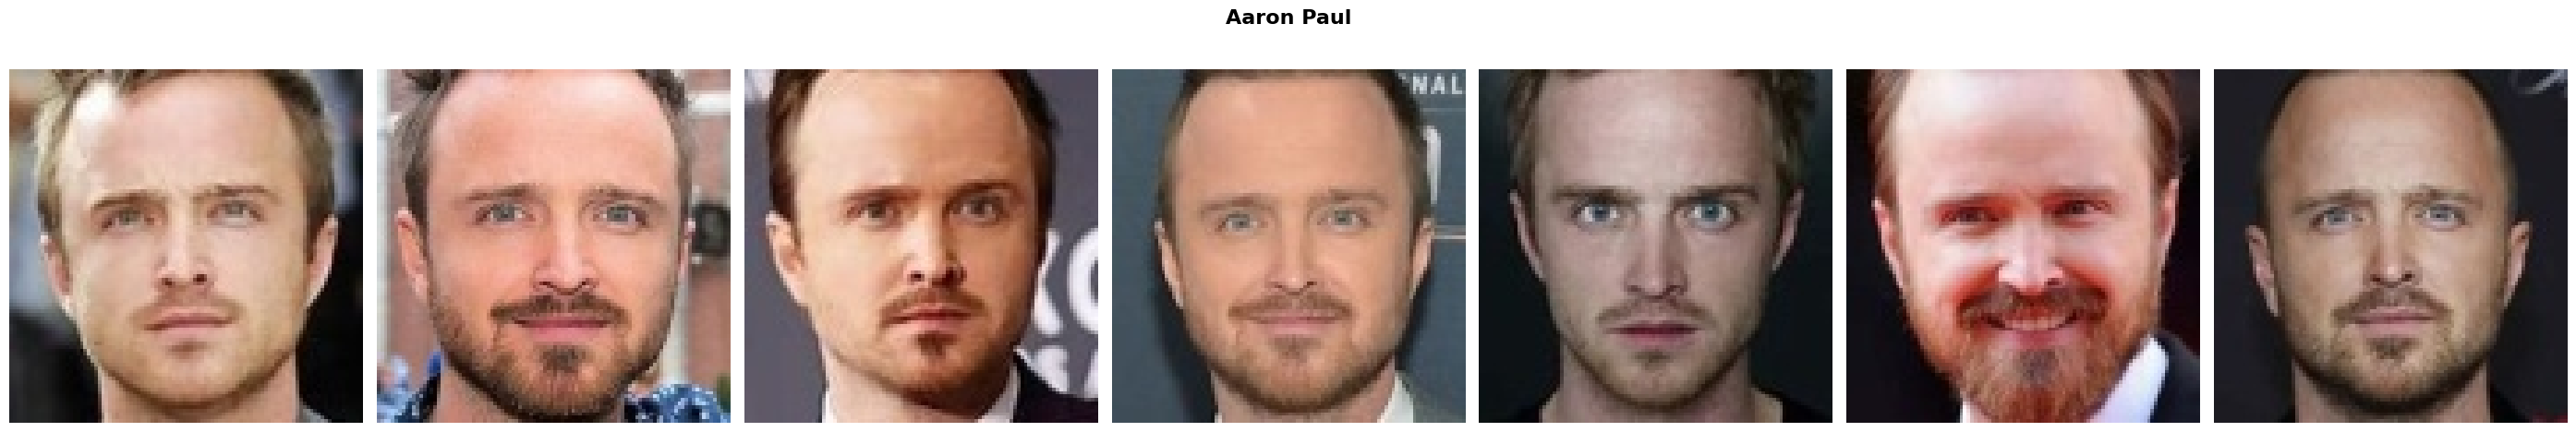

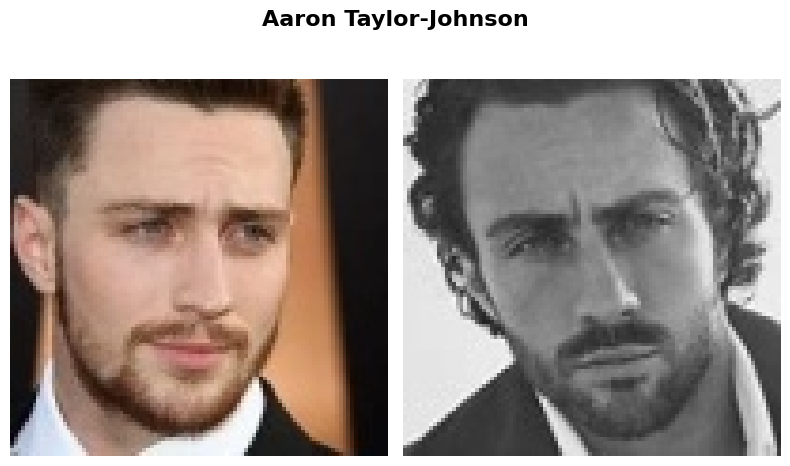

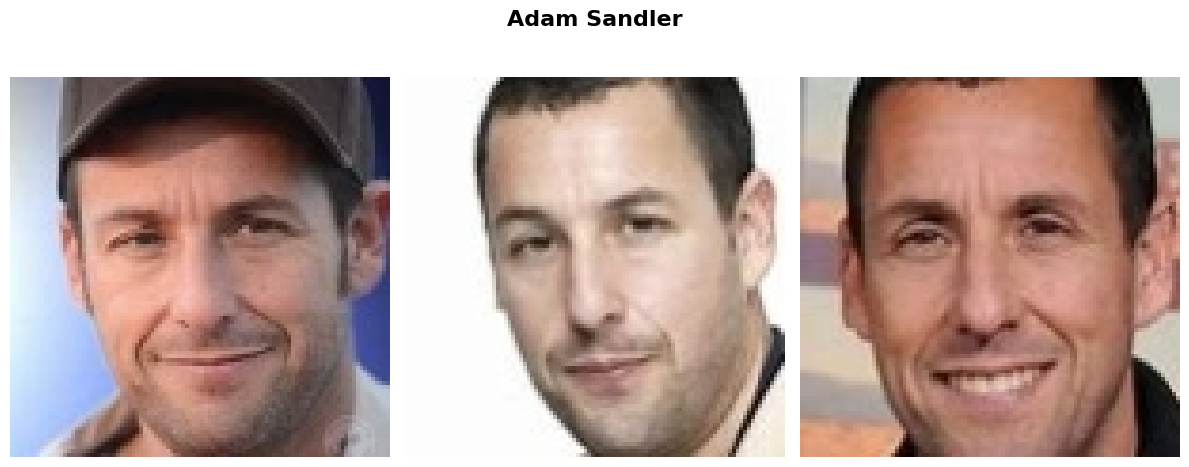

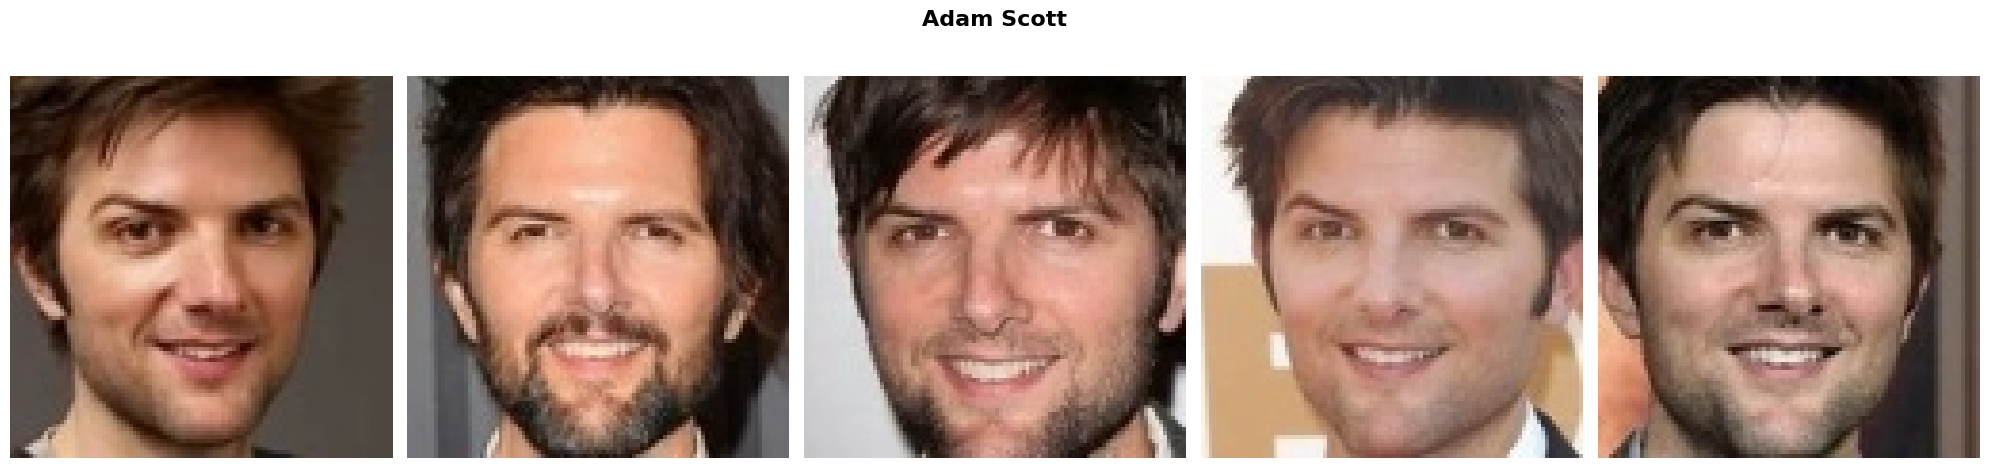

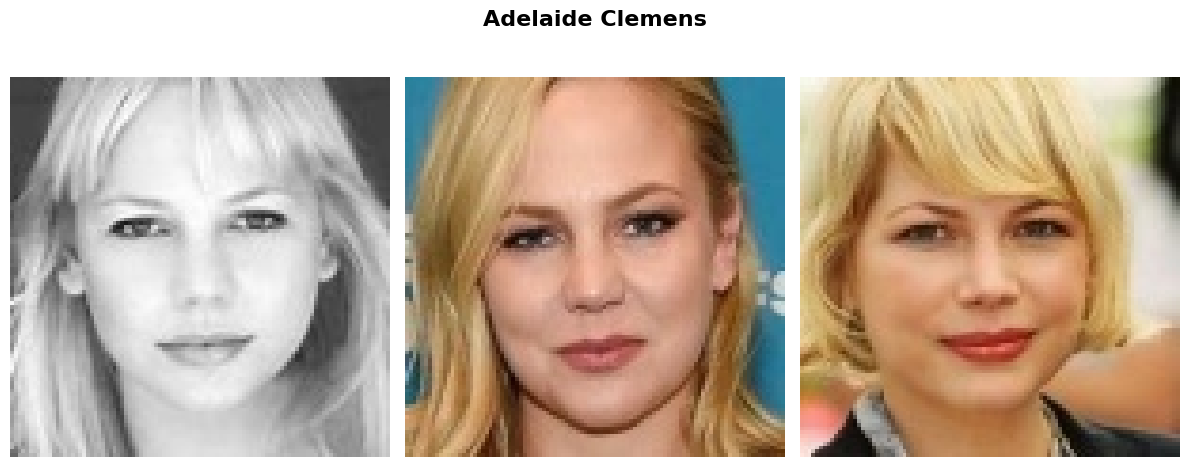

In [18]:
import os
import cv2
import matplotlib.pyplot as plt

for person, image_paths in list(info.items())[:5]:
    valid_images = []

    for image_path in image_paths:
        image = cv2.imread(image_path)

        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            valid_images.append(image)

    if not valid_images:
        continue

    fig, axes = plt.subplots(
        1, len(valid_images),
        figsize=(4 * len(valid_images), 5)
    )

    if len(valid_images) == 1:
        axes = [axes]

    fig.suptitle(person, fontsize=16, fontweight='bold')

    for ax, image in zip(axes, valid_images):
        ax.imshow(image)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [3]:
import google.protobuf
print("protobuf:", google.protobuf.__version__)

import insightface
print("insightface imported")

import onnxruntime
print("onnxruntime:", onnxruntime.__version__)

from insightface.app import FaceAnalysis
print("FaceAnalysis imported")

protobuf: 7.36.2
insightface imported
onnxruntime: 1.23.2
FaceAnalysis imported


In [5]:
app = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"])
app.prepare(
    ctx_id=-1,
    det_size=(640, 640))

download_path: C:\Users\kara/.insightface\models\buffalo_l


100%|██████████| 281857/281857 [02:56<00:00, 1598.61KB/s]


In [ ]:

import os
import cv2
import numpy as np
from tqdm import tqdm

app.prepare(ctx_id=-1, det_size=(320, 320))

all_embeddings = []
all_names = []
all_paths = []
failed_images = []

for person, image_paths in tqdm(info.items(), desc="Processing identities"):
    for image_path in image_paths:
        img = cv2.imread(image_path)

        if img is None:
            failed_images.append(image_path)
            continue

        faces = app.get(img)
        #یک لیست از اشیای مربوط به چهره‌های تشخیص‌داده‌شده است.
        #  هر شیء معمولاً اطلاعاتی مانند bounding box، نقاط کلیدی چهره و embedding را در اختیار می‌گذارد.

        if len(faces) == 0:
            failed_images.append(image_path)
            continue

        # اگر چند چهره وجود داشته باشد، بزرگ‌ترین چهره را انتخاب می‌کنیم.
        face = max(
            faces,
            key=lambda f: (
                (f.bbox[2] - f.bbox[0]) *
                (f.bbox[3] - f.bbox[1])
            )
        )

        embedding = face.embedding.astype(np.float32)

        # نرمال‌سازی بردار برای مقایسه‌ی کسینوسی
        embedding /= (np.linalg.norm(embedding) + 1e-10)

        all_embeddings.append(embedding)
        all_names.append(person)
        all_paths.append(image_path)

os.makedirs("face_database", exist_ok=True)

save_path = os.path.join("face_database", "embeddings.npz")

np.savez_compressed(
    save_path,
    embeddings=np.array(all_embeddings, dtype=np.float32),
    names=np.array(all_names),
    paths=np.array(all_paths)
)

print("Saved to:", os.path.abspath(save_path))
print("Successful images:", len(all_embeddings))
print("Failed images:", len(failed_images))
print("Unique identities:", len(set(all_names)))
print("Embedding matrix shape:", np.array(all_embeddings).shape)


Processing identities: 100%|██████████| 487/487 [07:49<00:00,  1.04it/s]


Saved to: c:\Users\kara\Desktop\DL\face_database\embeddings.npz
Successful images: 1907
Failed images: 5
Unique identities: 487
Embedding matrix shape: (1907, 512)


In [32]:
data = np.load("face_database/embeddings.npz")

embeddings = data["embeddings"]
names = data["names"]
paths = data["paths"]

print(embeddings.shape)
print(names.shape)

(1907, 512)
(1907,)


In [ ]:
from collections import Counter

counts = Counter(names)

print("Unique identities:", len(counts))
print("Images per identity:")
print(Counter(counts.values()))

Unique identities: 487
Images per identity:
Counter({4: 119, 3: 109, 2: 97, 5: 86, 6: 51, 7: 14, 8: 7, 9: 2, 1: 2})


In [34]:
eligible = {
    name: count
    for name, count in counts.items()
    if count >= 2
}

print("Identities with at least 2 images:", len(eligible))
print("Images belonging to these identities:", sum(eligible.values()))
print("Identities with only 1 image:", sum(count == 1 for count in counts.values()))

Identities with at least 2 images: 485
Images belonging to these identities: 1905
Identities with only 1 image: 2


In [35]:
import numpy as np

rng = np.random.default_rng(42)

gallery_idx = []
test_idx = []

for person in eligible:
    person_idx = np.where(names == person)[0]
    rng.shuffle(person_idx)

    test_idx.append(person_idx[0])
    gallery_idx.extend(person_idx[1:])

gallery_idx = np.array(gallery_idx)
test_idx = np.array(test_idx)

print("Gallery images:", len(gallery_idx))
print("Test images:", len(test_idx))
print("Identities in Gallery:", len(set(names[gallery_idx])))
print("Identities in Test:", len(set(names[test_idx])))

Gallery images: 1420
Test images: 485
Identities in Gallery: 485
Identities in Test: 485


In [36]:
gallery_embeddings = embeddings[gallery_idx]
test_embeddings = embeddings[test_idx]

similarity_matrix = test_embeddings @ gallery_embeddings.T

print("Similarity matrix:", similarity_matrix.shape)
print("Highest similarity for first test image:",
      similarity_matrix[0].max())

Similarity matrix: (485, 1420)
Highest similarity for first test image: 0.7853396


In [37]:
best_match_idx = np.argmax(similarity_matrix, axis=1)

predicted_names = names[gallery_idx][best_match_idx]
true_names = names[test_idx]

correct = predicted_names == true_names

print("Correct predictions:", correct.sum())
print("Total test images:", len(true_names))
print("Accuracy:", correct.mean())

Correct predictions: 475
Total test images: 485
Accuracy: 0.979381443298969


In [38]:
wrong_idx = np.where(~correct)[0]

for i in wrong_idx:
    print("True:", true_names[i])
    print("Predicted:", predicted_names[i])
    print("Best similarity:", similarity_matrix[i].max())
    print("Image:", paths[test_idx[i]])
    print("-" * 50)

True: Adelaide Clemens
Predicted: Michelle Williams
Best similarity: 0.73923683
Image: C:\Users\kara\Desktop\DL\faces\Adelaide Clemens\cropped_Adelaide Clemens_8.jpg
--------------------------------------------------
True: Anne Reid
Predicted: Jennifer Lawrence
Best similarity: 0.21817908
Image: C:\Users\kara\Desktop\DL\faces\Anne Reid\cropped_Anne Reid_1.jpg
--------------------------------------------------
True: Jared Gilman
Predicted: James Arnold Taylor
Best similarity: 0.19080554
Image: C:\Users\kara\Desktop\DL\faces\Jared Gilman\cropped_Jared Gilman_3.jpg
--------------------------------------------------
True: Jodi Carlisle
Predicted: Jennifer Garner
Best similarity: 0.36406627
Image: C:\Users\kara\Desktop\DL\faces\Jodi Carlisle\cropped_Jodi Carlisle_10.jpg
--------------------------------------------------
True: Kate Beckinsale
Predicted: David Spade
Best similarity: 0.2455676
Image: C:\Users\kara\Desktop\DL\faces\Kate Beckinsale\cropped_Kate Beckinsale_1.jpg
-----------------

In [39]:
best_scores = similarity_matrix.max(axis=1)

print("Correct prediction scores:")
print(best_scores[correct].min())
print(best_scores[correct].mean())
print(best_scores[correct].max())

print("\nWrong prediction scores:")
print(best_scores[~correct].min())
print(best_scores[~correct].mean())
print(best_scores[~correct].max())

Correct prediction scores:
0.18932384
0.6642984
0.9428961

Wrong prediction scores:
0.17434403
0.29146093
0.73923683


In [40]:
unique_names = np.array(list(eligible.keys()))
rng = np.random.default_rng(42)
rng.shuffle(unique_names)

split_point = int(len(unique_names) * 0.8)

known_people = set(unique_names[:split_point])
unknown_people = set(unique_names[split_point:])

print("Known identities:", len(known_people))
print("Unknown identities:", len(unknown_people))

Known identities: 388
Unknown identities: 97


In [41]:
known_mask = np.isin(names, list(known_people))
unknown_mask = np.isin(names, list(unknown_people))

known_indices = np.where(known_mask)[0]
unknown_indices = np.where(unknown_mask)[0]

print("Known images:", len(known_indices))
print("Unknown images:", len(unknown_indices))

Known images: 1519
Unknown images: 386


In [ ]:
rng = np.random.default_rng(42)

gallery_idx = []
known_test_idx = []

for person in known_people:
    person_idx = np.where(names == person)[0].copy()
    rng.shuffle(person_idx)

    known_test_idx.append(person_idx[0])
    gallery_idx.extend(person_idx[1:])

unknown_test_idx = unknown_indices.copy()

gallery_idx = np.array(gallery_idx)
known_test_idx = np.array(known_test_idx)
unknown_test_idx = np.array(unknown_test_idx)

print("Gallery images:", len(gallery_idx))
print("Known test images:", len(known_test_idx))
print("Unknown test images:", len(unknown_test_idx))
print("Known identities in Gallery:", len(set(names[gallery_idx])))
print("Unknown identities in Gallery:",
      len(set(names[gallery_idx]) & unknown_people))

Gallery images: 1131
Known test images: 388
Unknown test images: 386
Known identities in Gallery: 388
Unknown identities in Gallery: 0
